In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
data = pd.read_csv("student_placement_train.csv")

print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
display(data.head())

Dataset shape: (8000, 28)

Columns:
['student_id', 'age', 'gender', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score', 'preferred_domain', 'placed']

First 5 rows:


,student_id,age,gender,cgpa,attendance_percentage,backlogs,coding_score,aptitude_score,communication_score,technical_score,...,github_projects,linkedin_score,resume_score,soft_skills_score,leadership_score,extracurricular_score,training_hours,mock_interview_score,preferred_domain,placed
0,STU107218,21,Male,5.75,77.1,0,29.3,39.9,83.0,24.3,...,0,67.8,58.8,87.5,47.7,59.1,43.8,75.8,Data Science,0
1,STU108292,23,Male,7.14,NaN,0,61.7,63.4,55.3,49.0,...,5,53.5,77.8,77.9,71.2,34.5,102.3,70.8,Business Analytics,0
2,STU104608,23,Male,7.68,76.0,0,51.6,59.6,46.3,43.3,...,4,63.6,65.5,55.9,44.3,51.5,96.1,70.8,Business Analytics,0
3,STU105115,24,Male,6.07,75.8,1,24.0,47.5,75.0,65.1,...,3,65.7,59.8,75.6,90.9,54.4,118.5,91.1,Software Development,0
4,STU101860,20,Male,7.97,74.0,1,33.1,47.4,58.1,64.4,...,2,75.3,30.6,73.9,45.0,83.0,59.6,77.0,Business Analytics,0


In [ ]:
print(data.columns.tolist())

['student_id', 'age', 'gender', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score', 'preferred_domain', 'placed']


In [ ]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               8000 non-null   object 
 1   age                      8000 non-null   int64  
 2   gender                   8000 non-null   object 
 3   cgpa                     8000 non-null   float64
 4   attendance_percentage    7794 non-null   float64
 5   backlogs                 8000 non-null   int64  
 6   coding_score             7859 non-null   float64
 7   aptitude_score           7881 non-null   float64
 8   communication_score      7851 non-null   float64
 9   technical_score          7869 non-null   float64
 10  projects_count           8000 non-null   int64  
 11  major_projects           8000 non-null   int64  
 12  internships_count        8000 non-null   int64  
 13  internship_months        7762 non-null   float64
 14  certifications_count    

In [ ]:
print("\nMissing values:")
print(data.isnull().sum())
print("\nTarget distribution:")
print(data["placed"].value_counts())


Missing values:
student_id                   0
age                          0
gender                       0
cgpa                         0
attendance_percentage      206
backlogs                     0
coding_score               141
aptitude_score             119
communication_score        149
technical_score            131
projects_count               0
major_projects               0
internships_count            0
internship_months          238
certifications_count         0
hackathons_participated      0
hackathons_won               0
coding_platform_score        0
github_projects              0
linkedin_score             315
resume_score               189
soft_skills_score          154
leadership_score             0
extracurricular_score        0
training_hours             241
mock_interview_score       295
preferred_domain             0
placed                       0
dtype: int64

Target distribution:
placed
0    6370
1    1630
Name: count, dtype: int64


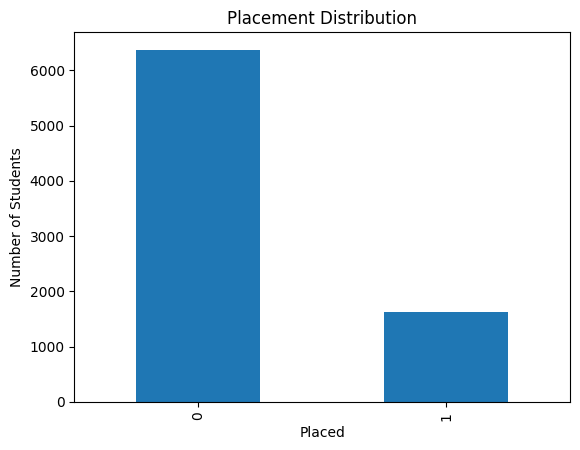

In [ ]:
data["placed"].value_counts().plot(kind="bar")
plt.xlabel("Placed")
plt.ylabel("Number of Students")
plt.title("Placement Distribution")
plt.show()

In [ ]:
X = data.drop("placed", axis=1)
y = data["placed"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Input features:
['student_id', 'age', 'gender', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score', 'preferred_domain']

Target:
placed


In [ ]:
id_columns = []

for column in X.columns:
    if "id" in column.lower():
        id_columns.append(column)

print("Possible ID columns:", id_columns)

Possible ID columns: ['student_id']


In [ ]:
X = X.drop(columns=id_columns)

print("Features after removing IDs:")
print(X.columns.tolist())

Features after removing IDs:
['age', 'gender', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score', 'preferred_domain']


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score']

Categorical features:
['gender', 'preferred_domain']


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 6400
Testing samples: 1600


In [ ]:
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.79625
Accuracy percentage: 79.62 %


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1274
           1       0.00      0.00      0.00       326

    accuracy                           0.80      1600
   macro avg       0.40      0.50      0.44      1600
weighted avg       0.63      0.80      0.71      1600



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1274
           1       0.00      0.00      0.00       326

    accuracy                           0.80      1600
   macro avg       0.40      0.50      0.44      1600
weighted avg       0.63      0.80      0.71      1600



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1274    0]
 [ 326    0]]


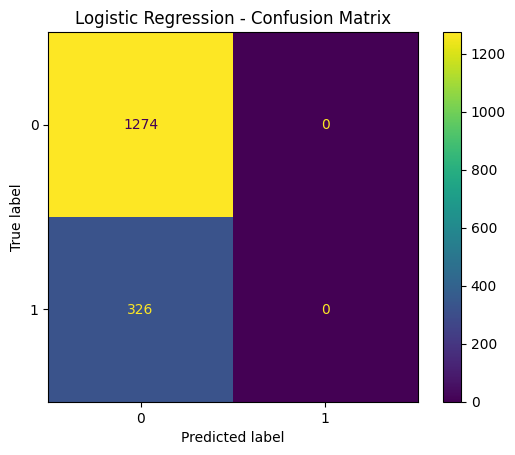

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
print("Number of input features:", len(X.columns))
print(X.columns.tolist())

Number of input features: 26
['age', 'gender', 'cgpa', 'attendance_percentage', 'backlogs', 'coding_score', 'aptitude_score', 'communication_score', 'technical_score', 'projects_count', 'major_projects', 'internships_count', 'internship_months', 'certifications_count', 'hackathons_participated', 'hackathons_won', 'coding_platform_score', 'github_projects', 'linkedin_score', 'resume_score', 'soft_skills_score', 'leadership_score', 'extracurricular_score', 'training_hours', 'mock_interview_score', 'preferred_domain']


In [ ]:
sample_student = X_test.iloc[[0]]

prediction = model.predict(sample_student)[0]
probability = model.predict_proba(sample_student)[0]

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: 0
Probability: [0.77579008 0.22420992]


In [ ]:
joblib.dump(model, "placement_logistic_model.pkl")

print("Model saved successfully!")

In [ ]:
import os

print(os.path.exists("placement_logistic_model.pkl"))

In [ ]:
from google.colab import files

files.download("placement_logistic_model.pkl")